# Week 9 demos

In [1]:
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

## Example 1: CalCOFI CTD / bottle cast

In this example, consider the quality-controlled oceanographic CTD and bottle dataset from the California Cooperative Oceanic Fisheries Investigations (CalCOFI). Our particular subset is from the July 2020 CalCOFI cruise conducted aboard the research vessel Sally Ride, and the data were collected during the downcast.

In [2]:
# Use urlretrieve to obtain the csv file
file_url = 'https://raw.githubusercontent.com/OCEAN-215-2026/week_09_demos/refs/heads/main/data/20-2007SR_CTDBTL_001-075D.csv'
urlretrieve(file_url, "data/20-2007SR_CTDBTL_001-075D.csv")

('data/20-2007SR_CTDBTL_001-075D.csv',
 <http.client.HTTPMessage at 0x7a1bbca58b90>)

In [3]:
# Load the CalCOFI CTD downcast data from July 2020
CalCOFI = pd.read_csv("data/20-2007SR_CTDBTL_001-075D.csv")
CalCOFI.info()

<class 'pandas.DataFrame'>
RangeIndex: 30071 entries, 0 to 30070
Data columns (total 82 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Project            30071 non-null  str    
 1   Study              30071 non-null  str    
 2   Ord_Occ            30071 non-null  int64  
 3   Event_Num          0 non-null      float64
 4   Cast_ID            30071 non-null  str    
 5   Date_Time_UTC      30071 non-null  str    
 6   Date_Time_PST      30071 non-null  str    
 7   Lat_Dec            30071 non-null  float64
 8   Lon_Dec            30071 non-null  float64
 9   Sta_ID             30071 non-null  str    
 10  Line               30071 non-null  float64
 11  Sta                30071 non-null  float64
 12  Depth              30071 non-null  float64
 13  Pressure           30071 non-null  float64
 14  PrQ                0 non-null      float64
 15  Temp1              30071 non-null  float64
 16  Temp1Q             0 non-null    

<!-- BEGIN QUESTION -->

### Poll #1 (JupyterHub **on**)

This cruise collected samples from a number of distinct stations, identified by their station ID `sta_ID`. How many stations were there?

+ 13
+ 75
+ 739
+ 30071

In [5]:
# Your code here
CalCOFI["Sta_ID"].nunique()

75

<!-- END QUESTION -->

Now let's focus on the deepest station. To identify the deepest station, we apply `.groupby()` with `.max()` on the `Depth` column

In [6]:
CalCOFI.loc[:, ["Sta_ID", "Depth"]]

,Sta_ID,Depth
0,093.4 026.4,2.0
1,093.4 026.4,3.0
2,093.4 026.4,4.0
3,093.4 026.4,5.0
4,093.4 026.4,6.0
...,...,...
30066,083.3 042.0,117.0
30067,083.3 042.0,118.0
30068,083.3 042.0,119.0
30069,083.3 042.0,120.0


In [7]:
# Use groupby to find the maximum depth of each station

CalCOFI_bySta = CalCOFI.loc[:, ["Sta_ID", "Depth"]].groupby("Sta_ID").max()

display(CalCOFI_bySta)

,Depth
Sta_ID,
076.7 049.0,61.0
076.7 051.0,231.0
076.7 055.0,516.0
076.7 060.0,516.0
076.7 070.0,517.0
...,...
093.3 090.0,517.0
093.3 100.0,517.0
093.3 110.0,516.0


In [9]:
# find the deepest sample
CalCOFI_bySta["Depth"].max()

740.0

In [10]:
# Extract the station whose maximum depth is the maximum (i.e., the deepest station)
CalCOFI_bySta.loc[CalCOFI_bySta["Depth"] == CalCOFI_bySta["Depth"].max()]

,Depth
Sta_ID,
086.7 040.0,740.0


In [11]:
# subset to the station with the deepest cast, and pick 3 variables to look at
Sta_87_40 = CalCOFI.loc[
    CalCOFI["Sta_ID"] == "086.7 040.0", 
    ["Depth", "TempAve", "SaltAve_Corr", "pH"]
]

In [12]:
display(Sta_87_40)

,Depth,TempAve,SaltAve_Corr,pH
14171,2.0,21.3821,33.7002,8.185
14172,3.0,21.4030,33.7017,8.185
14173,4.0,21.4499,33.7026,8.185
14174,5.0,21.4563,33.7021,8.185
14175,6.0,21.3600,33.6974,8.186
...,...,...,...,...
14905,736.0,5.3309,34.3867,7.507
14906,737.0,5.3297,34.3869,7.507
14907,738.0,5.3301,34.3869,7.508
14908,739.0,5.3292,34.3870,7.508


In [13]:
# Calculate the binned depth

Sta_87_40["Binned_Depth"] = 10 * (Sta_87_40["Depth"].astype(int) // 10) + 5

display(Sta_87_40)

,Depth,TempAve,SaltAve_Corr,pH,Binned_Depth
14171,2.0,21.3821,33.7002,8.185,5
14172,3.0,21.4030,33.7017,8.185,5
14173,4.0,21.4499,33.7026,8.185,5
14174,5.0,21.4563,33.7021,8.185,5
14175,6.0,21.3600,33.6974,8.186,5
...,...,...,...,...,...
14905,736.0,5.3309,34.3867,7.507,735
14906,737.0,5.3297,34.3869,7.507,735
14907,738.0,5.3301,34.3869,7.508,735
14908,739.0,5.3292,34.3870,7.508,735


<!-- BEGIN QUESTION -->

### Your turn #1

Calculate the bin-averaged temperature, salinity, and pH using a single group-by summarization. Call the resulting pandas dataframe `Sta_87_40_binned`

In [15]:
# Your code here
Sta_87_40_binned = (
    Sta_87_40
    .loc[:, ["Binned_Depth", "TempAve", "SaltAve_Corr", "pH"]]
    .groupby("Binned_Depth")
    .mean()
    .reset_index()
)

display(Sta_87_40_binned)

,Binned_Depth,TempAve,SaltAve_Corr,pH
0,5,21.327313,33.698663,8.185625
1,15,17.636770,33.584480,8.187600
2,25,14.703500,33.571920,8.153000
3,35,13.721130,33.569380,8.078600
4,45,12.681850,33.579210,7.987800
...,...,...,...,...
70,705,5.447320,34.377180,7.509800
71,715,5.422690,34.379280,7.508400
72,725,5.387330,34.382150,7.508700
73,735,5.336840,34.386240,7.507600


<!-- END QUESTION -->



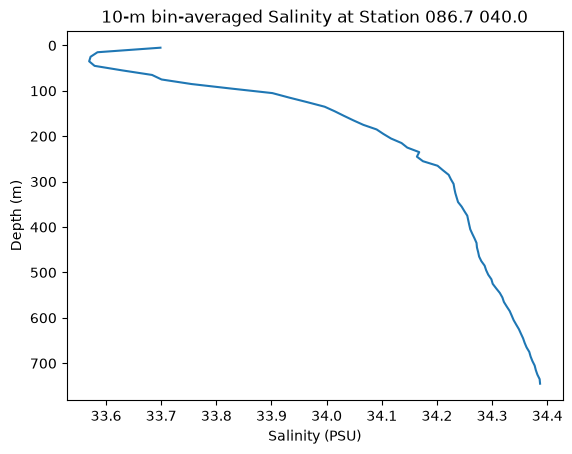

In [16]:
# let's plot one variable to see how it looks

fig = plt.figure()
ax = fig.add_subplot()

ax.plot(Sta_87_40_binned["SaltAve_Corr"], Sta_87_40_binned["Binned_Depth"])

ax.set_xlabel("Salinity (PSU)")
ax.set_ylabel("Depth (m)")
ax.set_title("10-m bin-averaged Salinity at Station 086.7 040.0")

ax.invert_yaxis()

plt.show(fig)

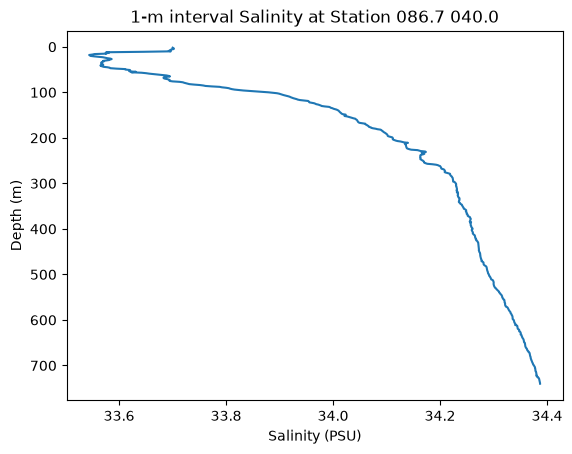

In [17]:
# Compare with the plot using raw data

fig = plt.figure()
ax = fig.add_subplot()

ax.plot(Sta_87_40["SaltAve_Corr"], Sta_87_40["Depth"])

ax.set_xlabel("Salinity (PSU)")
ax.set_ylabel("Depth (m)")
ax.set_title("1-m interval Salinity at Station 086.7 040.0")

ax.invert_yaxis()

plt.show(fig)

## Example 2: climatology and anomaly

In this second example we'll consider same sea ice concentration data that we considered in week 8. As with week 8 we will focus on the time dependence and thus we'll reduce the spatial dimensions.

In [18]:
# Use urlretrieve to obtain the csv file
file_url = 'https://raw.githubusercontent.com/OCEAN-215-2026/week_09_demos/refs/heads/main/data/icec.mnmean.nc'
#urlretrieve(file_url, "data/icec.mnmean.nc")

In [19]:
# same dataset, same subset and dimension reduction as in week 8

data = xr.open_dataset('data/icec.mnmean.nc')
ice = data["icec"]

ice_mean = ice.sel(lat = ice["lat"] > 45).mean(['lat', 'lon'])

ice_df = ice_mean.to_dataframe().reset_index()

display(ice_df)

,time,icec
0,1981-12-01,61.240326
1,1982-01-01,64.909760
2,1982-02-01,66.170067
3,1982-03-01,66.375320
4,1982-04-01,65.590027
...,...,...
489,2022-09-01,34.875526
490,2022-10-01,41.722862
491,2022-11-01,52.677277
492,2022-12-01,32.157875


<!-- BEGIN QUESTION -->

### Your turn #2

Create a new column called `month` that store the month of the ice thickness measurement

In [21]:
# Your code here
ice_df["month"] = ice_df["time"].dt.month
display(ice_df)

,time,icec,month
0,1981-12-01,61.240326,12
1,1982-01-01,64.909760,1
2,1982-02-01,66.170067,2
3,1982-03-01,66.375320,3
4,1982-04-01,65.590027,4
...,...,...,...
489,2022-09-01,34.875526,9
490,2022-10-01,41.722862,10
491,2022-11-01,52.677277,11
492,2022-12-01,32.157875,12


<!-- END QUESTION -->



In [22]:
# Now we can compute the ice thickness climatology
# by taking the mean over all years for a fixed month (Jan, Feb, etc.)

ice_mean_climatology = ice_df.loc[:, ["month", "icec"]].groupby("month").mean()
ice_mean_climatology

,icec
month,
1,62.752533
2,64.305946
3,64.729858
4,63.563011
5,60.455952
6,55.498737
7,47.175488
8,40.491695
9,38.416801


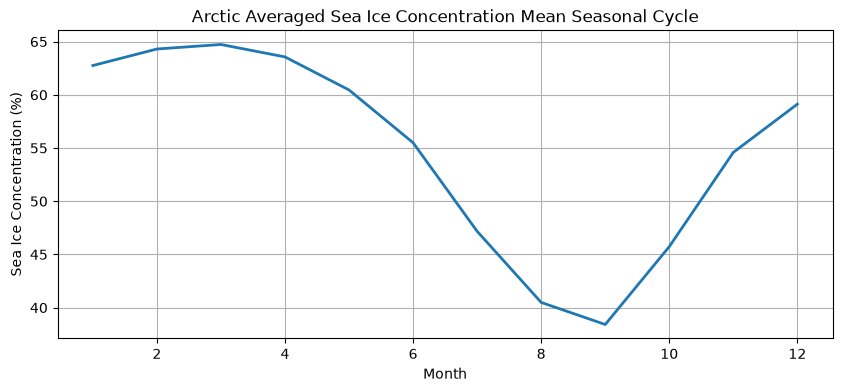

In [23]:
# Plot of the climatology

fig = plt.figure(figsize = (10, 4))
ax = fig.add_subplot()

ax.plot(ice_mean_climatology.index, ice_mean_climatology["icec"], lw=2)
ax.set_xlabel('Month')
ax.set_ylabel('Sea Ice Concentration (%)')
ax.set_title('Arctic Averaged Sea Ice Concentration Mean Seasonal Cycle')
ax.grid()

plt.show(fig)

In [28]:
ice_climatology_timeseries = ice_mean_climatology.loc[ice_df["month"], "icec"].values

In [29]:
# Next we calculate Anomalies
# These are deviations from the mean seasonal cycle

# for each row in ice_df, we want to extract the corresponding long-term mean of its ice concentration
# This is achieved using ice_mean_climatology.loc[ice_df["month"]]
# But pandas perform arithmetics by aligning indices, which would be wrong in our case
# To prevent that we extract the internal numpy array via .values

ice_df["anomalies"] = ice_df["icec"] - ice_climatology_timeseries
ice_df

,time,icec,month,anomalies
0,1981-12-01,61.240326,12,2.115326
1,1982-01-01,64.909760,1,2.157227
2,1982-02-01,66.170067,2,1.864120
3,1982-03-01,66.375320,3,1.645462
4,1982-04-01,65.590027,4,2.027016
...,...,...,...,...
489,2022-09-01,34.875526,9,-3.541275
490,2022-10-01,41.722862,10,-4.012177
491,2022-11-01,52.677277,11,-1.914921
492,2022-12-01,32.157875,12,-26.967125


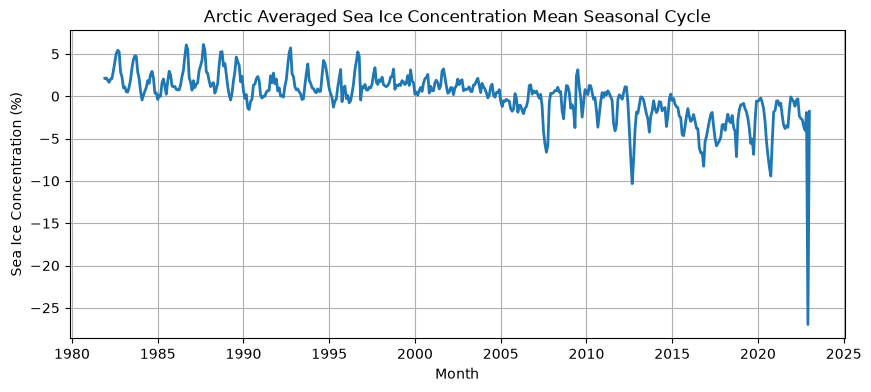

In [30]:
# Plot of the anomalies

fig = plt.figure(figsize = (10, 4))
ax = fig.add_subplot()

ax.plot(ice_df["time"], ice_df["anomalies"], lw=2)
ax.set_xlabel('Month')
ax.set_ylabel('Sea Ice Concentration (%)')
ax.set_title('Arctic Averaged Sea Ice Concentration Mean Seasonal Cycle')
ax.grid()

plt.show(fig)

<!-- BEGIN QUESTION -->

### Poll #2 (JupyterHub **on**)

Perform a linear regression on the anomalies. What portion of the variance is explained by the linear trend?

+ 33%
+ 44%
+ 56%
+ 67%

In [33]:
# Your code here

from scipy.stats import linregress

ice_time_day = (ice_df["time"] - ice_df["time"][0]) / np.timedelta64(1, 'D')

ice_trend = linregress(ice_time_day, ice_df["anomalies"].values)

print(ice_trend.slope)
print(ice_trend.rvalue)
print(ice_trend.rvalue ** 2)

-0.0004316131112311404
-0.6657759951103295
0.44325767566514945


<!-- END QUESTION -->



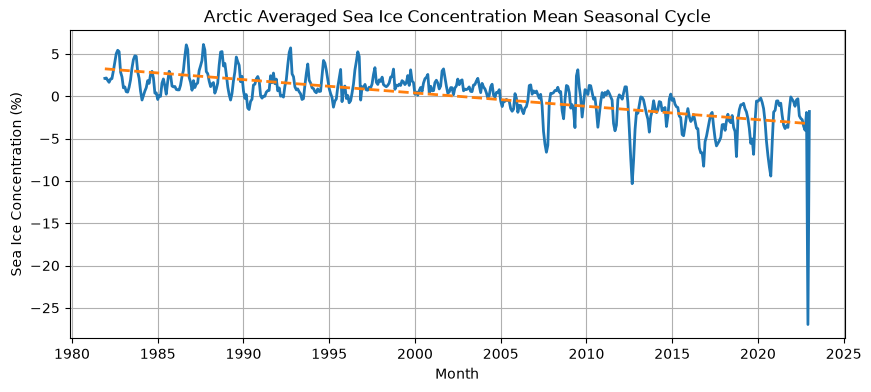

In [35]:
# Finally, let's visualize the best-fitted line

icec_pred = ice_trend.slope * ice_time_day + ice_trend.intercept

fig = plt.figure(figsize = (10, 4))
ax = fig.add_subplot()

ax.plot(ice_df["time"], ice_df["anomalies"], lw=2, label="anomalies")
ax.plot(ice_df["time"], icec_pred, lw=2, ls="--", label="best fitted line")

ax.set_xlabel('Month')
ax.set_ylabel('Sea Ice Concentration (%)')
ax.set_title('Arctic Averaged Sea Ice Concentration Mean Seasonal Cycle')
ax.grid()

plt.show(fig)
